In [0]:
import json, glob, csv
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
R = ROOT / "results"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 9, "axes.titlelocation": "left", "legend.frameon": False})
GREY, BLUE, ORANGE, GREEN, PURPLE = "#9E9E9E", "#5B7DB1", "#D35400", "#2E7D32", "#8E44AD"
def refs(ax, labels=True, x=None):
    for y, lab in [(8, "pyzx floor (8)"), (4, "Gidney (4)")]:
        ax.axhline(y, color="#555", lw=0.7, ls=(0, (3, 3)), zorder=0)
        if labels and x is not None:
            ax.text(x, y + 0.3, lab, fontsize=7, color="#555", ha="right")
print("results dir:", R)

results dir: /Users/shubdeepmohapatra/Documents/CircuitEvolve/results


## 1. Baselines: relaxing the specification halves the exact-unitary floor

Source: `results/baselines.csv` (`experiments/baselines.py`). Filled markers = verified by our exact verifier at that n;
open markers = T-count only (pyzx output is a dense circuit, exactly verified for n ≤ 5).

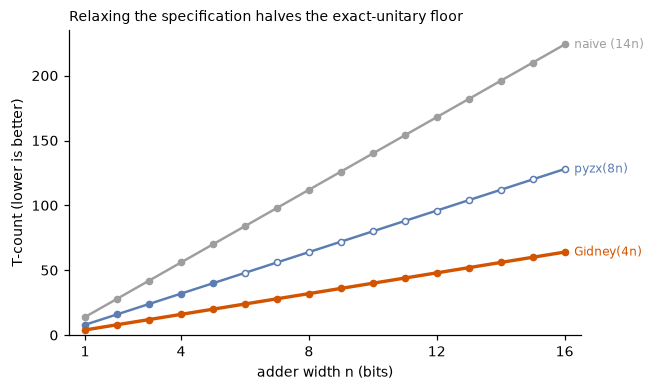

,t_per_bit,qubits_n16,t_depth_n16,verified_up_to_n
method,,,,
Gidney temporary AND,4.0,48,17,16
naive Cuccaro,14.0,34,128,16
pyzx full_reduce,8.0,34,101,5


In [2]:
df = pd.read_csv(R / "baselines.csv")
style = {"naive Cuccaro": (GREY, "naive (14n)"), "pyzx full_reduce": (BLUE, "pyzx(8n)"),
         "Gidney temporary AND": (ORANGE, "Gidney(4n)")}
fig, ax = plt.subplots(figsize=(6, 3.6))
for m, (col, lab) in style.items():
    g = df[df.method == m].sort_values("n")
    ax.plot(g.n, g.t_count, color=col, lw=2.2 if "Gidney" in m else 1.6)
    v, u = g[g.verified], g[~g.verified]
    ax.scatter(v.n, v.t_count, s=16, color=col, zorder=3)
    ax.scatter(u.n, u.t_count, s=16, facecolor="white", edgecolor=col, zorder=3)
    ax.text(g.n.iloc[-1] + 0.3, g.t_count.iloc[-1], lab, color=col, va="center", fontsize=8)
ax.set(xlabel="adder width n (bits)", ylabel="T-count (lower is better)", xlim=(0.5, 16.5), ylim=(0, 235),
       xticks=[1, 4, 8, 12, 16], title="Relaxing the specification halves the exact-unitary floor")
plt.show()
summary = df.assign(t_per_bit=df.t_count / df.n).groupby("method").agg(
    t_per_bit=("t_per_bit", "mean"), qubits_n16=("qubits", "last"), t_depth_n16=("t_depth", "last"),
    verified_up_to_n=("n", lambda s: int(s[df.loc[s.index, "verified"]].max())))
summary

## 2. Classical search (P3): reaches 4n only when the carry structure is given

Source: `results/runs/*.json` (`experiments/search_classical.py`): mutation-only MAP-Elites, 3 seeds × 3×10⁴ evaluations.
The table below the figure also lists the separate, longer runs with crossover (`results/classical_search_strong.csv`),
which were stopped early and are **not** in the figure.

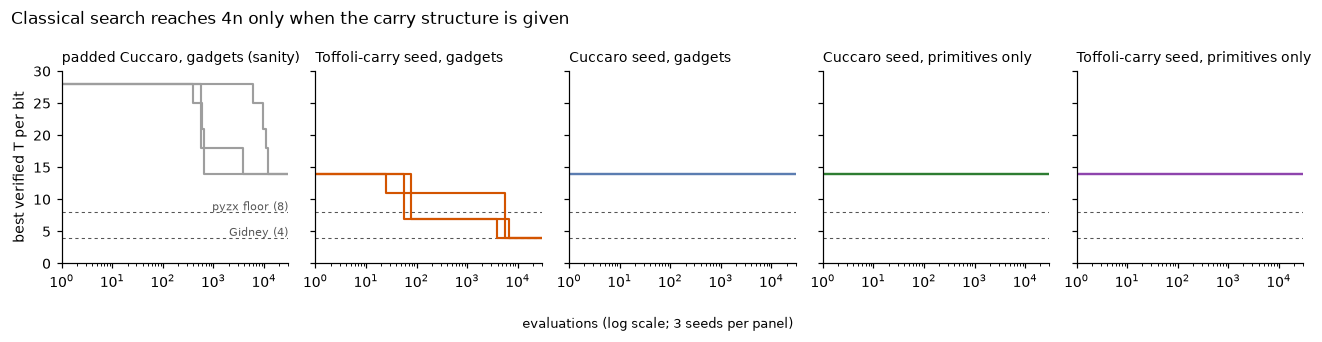

,seeds,evals_per_run,best_t_per_bit,worst_t_per_bit,all_verified_n1_16
config,,,,,
sanity_padded_A,3,30000,14.0,14.0,True
toffoli_carry_A,3,30000,4.0,4.0,True
cuccaro_A,3,30000,14.0,14.0,True
cuccaro_B,3,30000,14.0,14.0,True
toffoli_carry_B,3,30000,14.0,14.0,True


,seeds,evals_min,evals_max,best_t_per_bit
config,,,,
cuccaro_A,3,320000,400000,14.0
cuccaro_B,3,120000,220000,14.0
toffoli_carry_B,3,160000,220000,14.0


In [4]:
runs = [json.load(open(f)) for f in sorted(glob.glob(str(R / "runs" / "*.json")))]
order = ["sanity_padded_A", "toffoli_carry_A", "cuccaro_A", "cuccaro_B", "toffoli_carry_B"]
label = {"sanity_padded_A": "padded Cuccaro, gadgets (sanity)", "toffoli_carry_A": "Toffoli-carry seed, gadgets",
         "cuccaro_A": "Cuccaro seed, gadgets", "cuccaro_B": "Cuccaro seed, primitives only",
         "toffoli_carry_B": "Toffoli-carry seed, primitives only"}
color = {"sanity_padded_A": GREY, "toffoli_carry_A": ORANGE, "cuccaro_A": BLUE, "cuccaro_B": GREEN, "toffoli_carry_B": PURPLE}
B = 30000
fig, axes = plt.subplots(1, 5, figsize=(12, 3), sharey=True)
for ax, c in zip(axes, order):
    for r in [r for r in runs if r["config"] == c]:
        tr = r["trajectory"]
        ax.step([max(e, 1) for e, _ in tr] + [B], [v for _, v in tr] + [tr[-1][1]], where="post", color=color[c], lw=1.4)
    refs(ax, labels=(ax is axes[0]), x=B)
    ax.set(xscale="log", xlim=(1, B), ylim=(0, 30), title=label[c])
    ax.title.set_color(color[c]); ax.title.set_fontsize(8)
axes[0].set_ylabel("best verified T per bit")
fig.supxlabel("evaluations (log scale; 3 seeds per panel)", fontsize=8.5)
fig.suptitle("Classical search reaches 4n only when the carry structure is given", x=0.01, ha="left")
fig.tight_layout(); plt.show()

p3 = pd.read_csv(R / "classical_search.csv")
p3_tab = p3.groupby("config").agg(seeds=("rng_seed", "count"), evals_per_run=("evals", "max"),
                                  best_t_per_bit=("t_per_bit", "min"), worst_t_per_bit=("t_per_bit", "max"),
                                  all_verified_n1_16=("final_verify_n1_16", "all"))
strong = pd.read_csv(R / "classical_search_strong.csv")
strong_tab = strong.groupby("config").agg(seeds=("rng_seed", "count"), evals_min=("evals", "min"),
                                          evals_max=("evals", "max"), best_t_per_bit=("t_per_bit", "min"))
display(p3_tab.reindex(order)); display(strong_tab)

## 3. LLM + local repair, primitives only: 14n → 4n in 54 calls

Source: `results/llm_runs/cuccaro_B_open_evo_repair300_120.summary.json` (single seed, 120 LLM calls).
Best verified T per bit after each LLM call. Each call returns 4 proposals; a rejected proposal gets up to 300
random 1–2-gate edits ("local repair"), and the first edit that passes the exact verifier is kept.
Labels give the call and the cumulative verified evaluations (proposals + repair edits) at each improvement.
For comparison: classical search on this row stayed at 14 T/bit (Section 2).

total: 120 calls, 67,172 verified evaluations, 69 accepted programs (35 via repair)


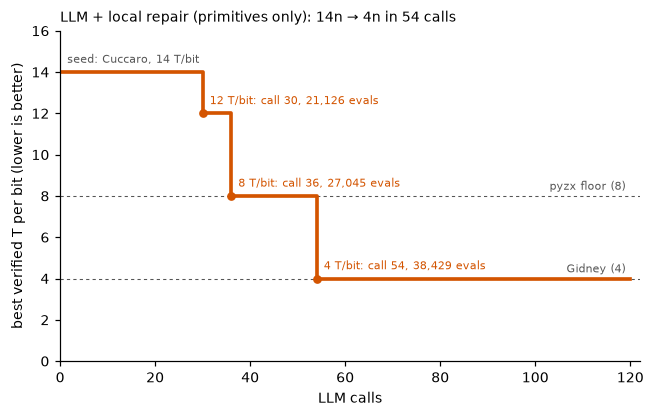

In [6]:
L = R / "llm_runs"
hyb = json.load(open(L / "cuccaro_B_open_evo_repair300_120.summary.json"))
tr = hyb["trajectory"]                                   # (LLM calls, verified evaluations, best T per bit)
fig, ax = plt.subplots(figsize=(6.8, 3.9))
ax.step([c for c, e, v in tr], [v for c, e, v in tr], where="post", color=ORANGE, lw=2.4)
refs(ax, x=119)
prev = tr[0][2]
for c, e, v in tr:
    if v < prev:
        ax.scatter([c], [v], s=22, color=ORANGE, zorder=3)
        ax.text(c + 1.5, v + 0.45, f"{v:g} T/bit: call {c}, {e:,} evals", fontsize=7.5, color=ORANGE)
        prev = v
ax.text(1.5, 14.45, "seed: Cuccaro, 14 T/bit", fontsize=7.5, color="#555")
ax.set(xlim=(0, 122), ylim=(0, 16), xlabel="LLM calls", ylabel="best verified T per bit (lower is better)",
       title="LLM + local repair (primitives only): 14n → 4n in 54 calls")
plt.show()
print(f"total: {hyb['stats']['calls']} calls, {hyb['stats']['evals']:,} verified evaluations, "
      f"{hyb['stats']['accepted']} accepted programs ({hyb['stats']['repaired']} via repair)")

### Per-arm proposal statistics (from the call logs)
`pass` = accepted directly; `->repaired` = rejected, then fixed by local repair; L0/L1/L2 = verifier level that rejected it.

In [8]:
from collections import Counter
rows = []
for name, f in [("hybrid (repair 300)", "cuccaro_B_open_evo_repair300_120.jsonl"), ("LLM only", "cuccaro_B_open_evo_120.jsonl"),
                ("zero-shot, original", "pilot_cuccaro_B_open_zeroshot.jsonl"), ("zero-shot, blinded", "pilot_cuccaro_B_blind_zeroshot.jsonl"),
                ("evolution, blinded", "pilot_cuccaro_B_blind_evo.jsonl")]:
    recs = [json.loads(l) for l in open(L / f)]
    v = Counter(x for r in recs for x in r.get("verdicts", []))
    rows.append({"arm": name, "calls": recs[-1]["call"], "proposals": sum(v.values()),
                 "accepted_direct": v["pass"], "repaired": sum(n for k, n in v.items() if k.endswith("repaired")),
                 "rejected_L1": v["L1"], "rejected_L2": v["L2"], "duplicates": v["duplicate"],
                 "best_t_per_bit": min([r["best"][0] for r in recs if "best" in r] + [14.0])})
pd.DataFrame(rows).set_index("arm")

,calls,proposals,accepted_direct,repaired,rejected_L1,rejected_L2,duplicates,best_t_per_bit
arm,,,,,,,,
hybrid (repair 300),120,479,34,35,232,43,125,4.0
LLM only,78,271,5,0,232,3,23,7.0
"zero-shot, original",24,96,1,0,88,3,0,8.0
"zero-shot, blinded",24,95,0,0,78,4,1,14.0
"evolution, blinded",24,80,1,0,71,0,5,14.0


## 4. The discovered 4n program, re-verified

Loads `results/discovered/hybrid_4n_primitives.py` and runs the full exact verifier (all levels, gadget shortcut off) for n = 1..16,
then compares costs with the Gidney reference.

In [10]:
import sys, importlib.util, time
sys.path.insert(0, str(ROOT))
from circuitevolve.search.slice import build, to_source
from circuitevolve.verify import verify
from circuitevolve.spec import AdderSpec
from circuitevolve.ir import TIER_B
from circuitevolve.cost import cost
from circuitevolve.baselines import gidney
spec_ = importlib.util.spec_from_file_location("found", R / "discovered" / "hybrid_4n_primitives.py")
found = importlib.util.module_from_spec(spec_); spec_.loader.exec_module(found)
print(to_source(found.PROGRAM))
t = time.time()
rep = verify(lambda n: build(found.PROGRAM, n), AdderSpec(), list(range(1, 17)), TIER_B)
print(f"exact verification n = 1..16: {'PASS' if rep.ok else 'FAIL ' + rep.level + ' ' + rep.reason} ({time.time() - t:.1f} s)")
pd.DataFrame({"found (LLM + repair)": rep.costs[16], "Gidney reference": cost(gidney.construct_tier_b(16))}).T[
    ["t_count", "t_depth", "cnot", "qubits", "measurements"]]

FWD = (
    G('cx', 'a', 'b'),
    G('cx', 'a', 'pa'),
    G('h', 'cout'),
    G('t', 'cout'),
    G('cx', 'b', 'cout'),
    G('tdg', 'cout'),
    G('cx', 'pa', 'cout'),
    G('t', 'cout'),
    G('cx', 'b', 'cout'),
    G('tdg', 'cout'),
    G('cx', 'pa', 'cout'),
    G('h', 'cout'),
    G('cx', 'cout', 'a'),
)
TOP = (
    G('cx', 'a', 'z'),
)
BWD = (
    G('cx', 'cout', 'a'),
    G('s', 'cout'),
    G('h', 'cout'),
    G('measure', 'cout', label='m'),
    G('cz', 'b', 'pa', cond='m'),
    G('x', 'cout', cond='m'),
    G('cx', 'a', 'pa'),
    G('cx', 'pa', 'b'),
)

exact verification n = 1..16: PASS (1.1 s)


,t_count,t_depth,cnot,qubits,measurements
found (LLM + repair),64,34,161,50,16
Gidney reference,64,17,186,48,15
